# 07 · Clasificador preentrenado (EfficientNet-B0) sobre recortes

**Problema de las CNN originales** (notebooks 01–03): se entrenaban desde cero con ~270 fotos reducidas a 256×256 px (20 veces más chicas que el original). El mejor modelo detectaba solo el **22 %** de las piezas NO OK, y el notebook 03 no llegó a converger.

**Solución:**
- Usar una red **preentrenada en ImageNet** (EfficientNet-B0 de `timm`), que ya sabe reconocer texturas y bordes.
- Entrenarla con **recortes de 512 px a resolución nativa** (defecto / limpio), usando las cajas anotadas como supervisión.
- Muestreo balanceado: cada lote tiene ~50 % de recortes con defecto.
- En inferencia, el **score de la toalla es el máximo** sobre todos sus recortes. Basta un recorte sospechoso para marcar la toalla.
- **Minería de negativos difíciles:** como basta un recorte para marcar la toalla, los recortes limpios que el modelo confunde generan falsas alarmas. Tras el primer entrenamiento se califican *todos* los recortes de las toallas OK de entrenamiento. Los que superan 0.2 (2,601 recortes) se agregan como "limpio" con triple peso y se reentrena 6 épocas. En test, el AUC por toalla subió de 0.888 a 0.935.

```bash
python scripts/06_train_tile_classifier.py --arch efficientnet_b0 --epochs 15
cp models/tile_cls_efficientnet_b0.pt models/tile_cls_efficientnet_b0_v1.pt
python scripts/06b_mine_hard_negatives.py --weights models/tile_cls_efficientnet_b0_v1.pt
python scripts/06_train_tile_classifier.py --init models/tile_cls_efficientnet_b0_v1.pt --epochs 6 --lr 1e-4 --hn-weight 3
# alternativa: --arch resnet50
```

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, average_precision_score
from torchvision import datasets, transforms
from galia import config as C, viz
from galia.data import load_manifest, load_image, load_boxes
from galia.models import ClassifierTilePredictor
viz.setup()
ARCH = "efficientnet_b0"
WEIGHTS = C.MODELS_DIR / f"tile_cls_{ARCH}.pt"

## 1. Entrenamiento

,epoch,train_loss,val_ap,val_auc,val_recall_at_0_5
16,17,0.1346,0.7439,0.8896,0.6695
17,18,0.1108,0.7541,0.8945,0.6442
18,19,0.0825,0.7429,0.8919,0.6189
19,20,0.0641,0.7451,0.8934,0.6063
20,21,0.0582,0.7431,0.8932,0.6147


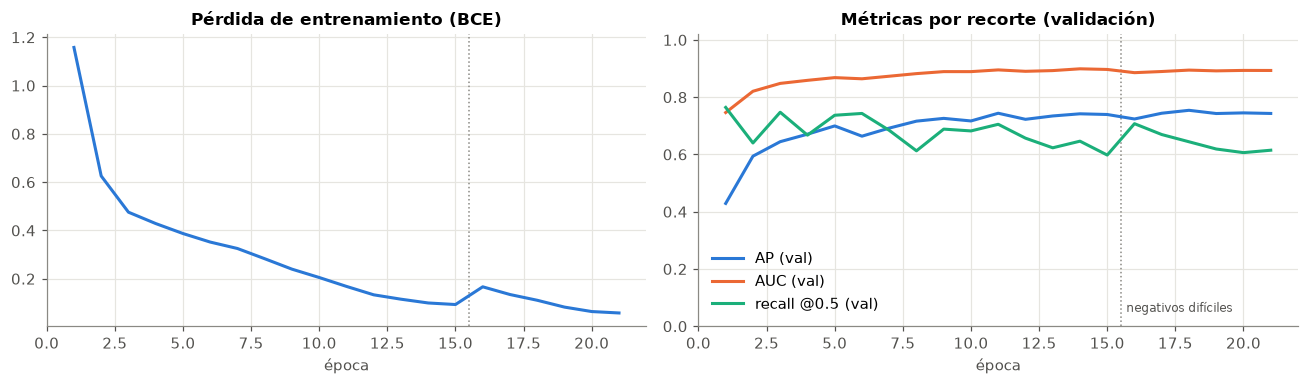

In [2]:
run = C.RUNS_DIR / f"tile_cls_{ARCH}"
h1 = pd.DataFrame(json.loads((run / "history_v1.json").read_text()))
h2 = pd.DataFrame(json.loads((run / "history.json").read_text())); h2["epoch"] += len(h1)
hist = pd.concat([h1, h2], ignore_index=True)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax in axes:
    ax.axvline(len(h1) + 0.5, color="#8a8984", lw=1, ls=":")
axes[1].text(len(h1) + 0.7, 0.05, "negativos difíciles", fontsize=8, color="#52514e")
axes[0].plot(hist.epoch, hist.train_loss); axes[0].set_title("Pérdida de entrenamiento (BCE)"); axes[0].set_xlabel("época")
axes[1].plot(hist.epoch, hist.val_ap, label="AP (val)")
axes[1].plot(hist.epoch, hist.val_auc, label="AUC (val)")
axes[1].plot(hist.epoch, hist.val_recall_at_0_5, label="recall @0.5 (val)")
axes[1].set_ylim(0, 1.02); axes[1].set_xlabel("época"); axes[1].legend(); axes[1].set_title("Métricas por recorte (validación)")
plt.tight_layout()
hist.round(4).tail(5)

## 2. Desempeño por recorte (validación)

C:\Users\Marcony1\miniconda3\envs\galia_v2\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2695 recortes de validación (475 con defecto)


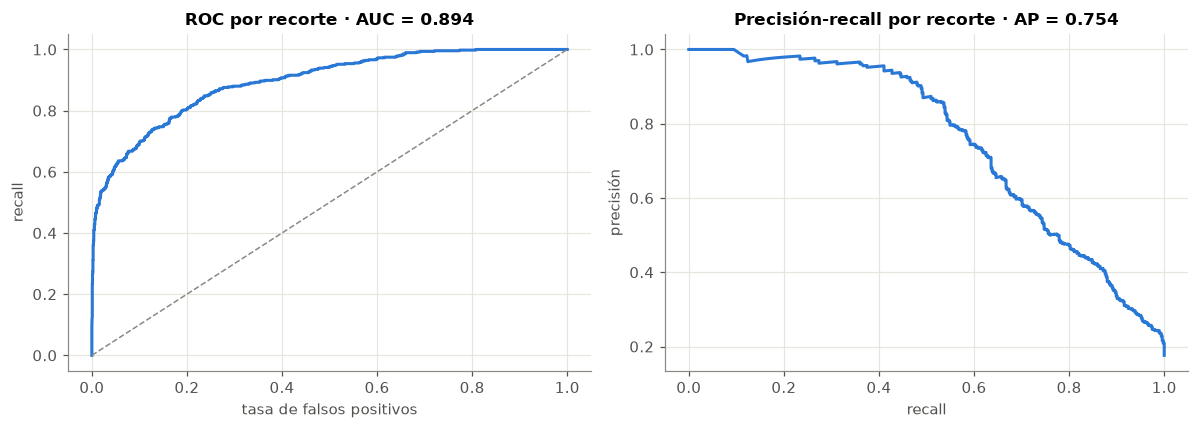

In [3]:
ck = torch.load(WEIGHTS, map_location="cpu", weights_only=False)
from galia.models import build_classifier
model = build_classifier(ck["arch"], pretrained=False); model.load_state_dict(ck["state_dict"])
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu"); model.to(dev).eval()
tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
ds = datasets.ImageFolder(C.CLS_TILES_DIR / "val", transform=tf)
dl = torch.utils.data.DataLoader(ds, batch_size=48, num_workers=2)
ps, ys = [], []
with torch.no_grad():
    for x, y in dl:
        with torch.autocast(dev.type, enabled=dev.type == "cuda"):
            ps.append(torch.sigmoid(model(x.to(dev)).float()).squeeze(1).cpu()); ys.append(y)
p, y = torch.cat(ps).numpy(), torch.cat(ys).numpy()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
fpr, tpr, _ = roc_curve(y, p); axes[0].plot(fpr, tpr)
axes[0].plot([0, 1], [0, 1], color="#8a8984", lw=1, ls="--")
axes[0].set_title(f"ROC por recorte · AUC = {roc_auc_score(y, p):.3f}"); axes[0].set_xlabel("tasa de falsos positivos"); axes[0].set_ylabel("recall")
pr, rc, _ = precision_recall_curve(y, p); axes[1].plot(rc, pr)
axes[1].set_title(f"Precisión-recall por recorte · AP = {average_precision_score(y, p):.3f}"); axes[1].set_xlabel("recall"); axes[1].set_ylabel("precisión")
plt.tight_layout()
print(f"{len(y)} recortes de validación ({y.sum()} con defecto)")

### Recortes con defecto que el clasificador califica más bajo (los más difíciles)

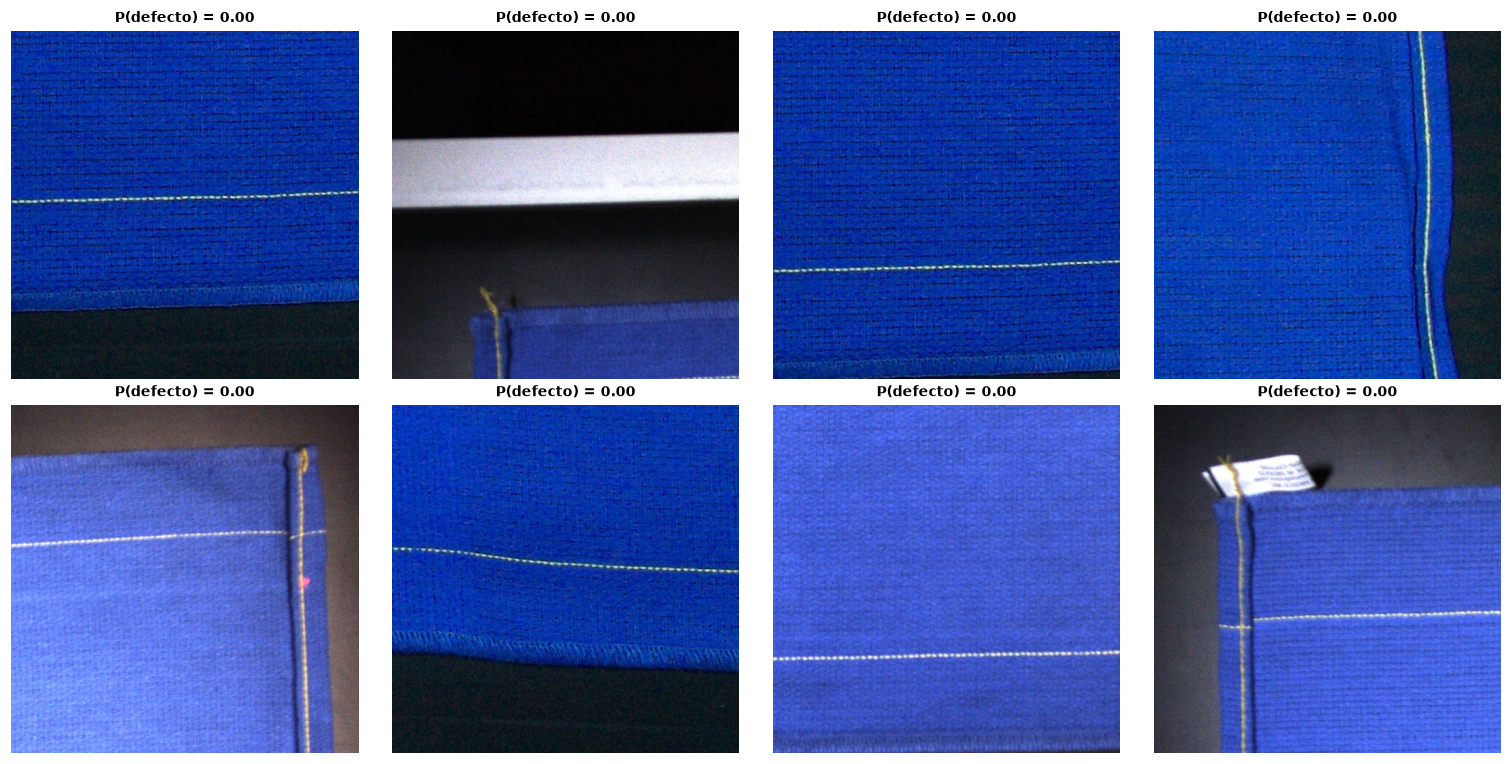

In [4]:
idx_def = np.where(y == 1)[0]; hard = idx_def[np.argsort(p[idx_def])[:8]]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, i in zip(axes.flat, hard):
    ax.imshow(plt.imread(ds.samples[i][0])); ax.set_axis_off()
    ax.set_title(f"P(defecto) = {p[i]:.2f}", fontsize=9)
plt.tight_layout()

## 3. Mapa de calor sobre toallas completas (test)
Cada recorte de 512 px recibe una probabilidad de defecto. El mapa muestra dónde se concentra la sospecha.

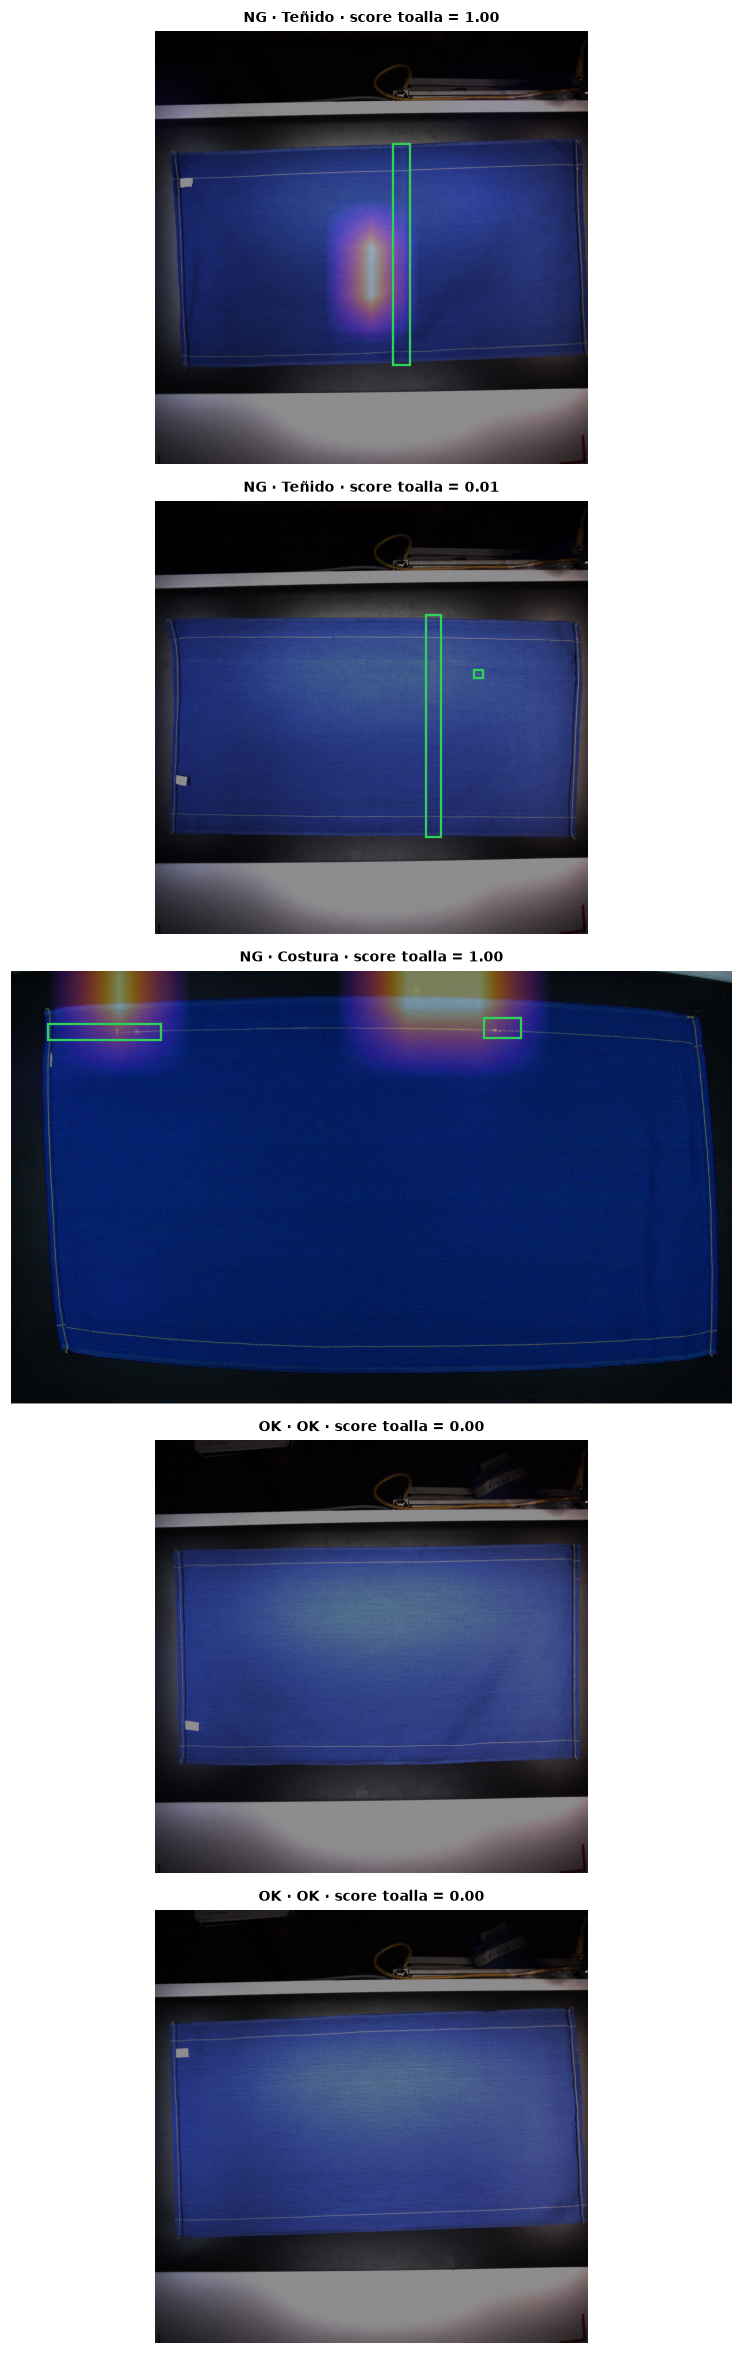

In [5]:
pred = ClassifierTilePredictor(WEIGHTS)
df = load_manifest(); test = df[df.split == "test"]
ex = pd.concat([test[(test.label == "NG") & (test.n_defect_boxes > 0)].sample(3, random_state=7),
                test[test.label == "OK"].sample(2, random_state=7)])
fig, axes = plt.subplots(len(ex), 1, figsize=(10, 4.3 * len(ex)))
for ax, r in zip(axes, ex.itertuples()):
    img, s = load_image(r.path, r.source)
    out = pred(img)
    viz.overlay_heatmap(ax, img, out.heatmap, vmax=1.0, alpha=0.45,
                        title=f"{r.label} · {r.category} · score toalla = {out.score:.2f}")
    if r.label_path:
        b = load_boxes(r.label_path, r.width, r.height); b[:, 1:] *= s
        for c, x1, y1, x2, y2 in b:
            if int(c) in C.DEFECT_CLASS_IDS:
                ax.add_patch(plt.Rectangle((x1 - 20, y1 - 20), x2 - x1 + 40, y2 - y1 + 40, fill=False, ec="#30d158", lw=1.5))
plt.tight_layout()